#### PIPs needed


###### yfinance
###### matplotlib
###### scipy
###### nsepython (failed)
###### playwright (failed)
###### chromium (failed)
###### statsmodels

### Importing Necessary Libraries

In [1]:
import math
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
from scipy import stats
from scipy.stats import norm, laplace, t as student_t, genextreme, gennorm

### Calling the data

In [2]:
adani = yf.download('ADANIENT.NS', start='2022-01-01', end='2025-12-31', auto_adjust=True)
hul = yf.download('HINDUNILVR.NS', start='2022-01-01', end='2025-12-31', auto_adjust=True)
tatamotors = yf.download(
    "TATAMOTORS.NS",
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=True
)

print(tatamotors)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TATAMOTORS.NS"}}}
$TATAMOTORS.NS: possibly delisted; no timezone found
[*********************100%***********************]  1 of 1 completed

1 Failed download:
['TATAMOTORS.NS']: possibly delisted; no timezone found


Empty DataFrame
Columns: [(Adj Close, TATAMOTORS.NS), (Close, TATAMOTORS.NS), (High, TATAMOTORS.NS), (Low, TATAMOTORS.NS), (Open, TATAMOTORS.NS), (Volume, TATAMOTORS.NS)]
Index: []


In [3]:
adani.head()

Price,Close,High,Low,Open,Volume
Ticker,ADANIENT.NS,ADANIENT.NS,ADANIENT.NS,ADANIENT.NS,ADANIENT.NS
Date,,,,,
2022-01-03,1713.325317,1729.139989,1707.388497,1709.184537,1094708
2022-01-04,1715.171265,1724.151219,1696.213583,1721.906230,1191189
2022-01-05,1711.629150,1740.764187,1698.757980,1718.164610,1583598
2022-01-06,1709.284302,1720.010358,1671.867827,1706.191231,1615375
2022-01-07,1695.315430,1726.944895,1685.736837,1716.069149,1295933


In [4]:
hul.head()

Price,Close,High,Low,Open,Volume
Ticker,HINDUNILVR.NS,HINDUNILVR.NS,HINDUNILVR.NS,HINDUNILVR.NS,HINDUNILVR.NS
Date,,,,,
2022-01-03,2178.458740,2193.865573,2170.801385,2193.865573,879278
2022-01-04,2215.315430,2221.635108,2172.969667,2185.516451,1484275
2022-01-05,2228.738770,2232.613508,2206.781616,2217.667959,1202512
2022-01-06,2206.228027,2225.233010,2184.363221,2212.317063,1198901
2022-01-07,2229.061768,2234.366532,2203.091578,2203.091578,1026186


### Computing returns

In [68]:
adani['log_return'] = np.log(adani['Close'] / adani['Close'].shift(1))
adani['arith_return'] = adani['Close'].diff()
adani = adani.dropna()

hul['log_return'] = np.log(hul['Close'] / hul['Close'].shift(1))
hul['arith_return'] = hul['Close'].diff()
hul = hul.dropna()

adani[['Close', 'log_return', 'arith_return']].head()

Price,Close,log_return,arith_return
Ticker,ADANIENT.NS,,
Date,,,
2022-01-07,1695.315430,-0.008206,-13.968872
2022-01-10,1748.696289,0.031002,53.380859
2022-01-11,1839.792969,0.050783,91.096680
2022-01-12,1826.023804,-0.007512,-13.769165
2022-01-13,1849.221924,0.012624,23.198120


In [7]:
hul[['Close', 'log_return', 'arith_return']].head()

Price,Close,log_return,arith_return
Ticker,HINDUNILVR.NS,,
Date,,,
2022-01-04,2215.315674,0.016777,36.856689
2022-01-05,2228.738770,0.006041,13.423096
2022-01-06,2206.228027,-0.010152,-22.510742
2022-01-07,2229.061279,0.010296,22.833252
2022-01-10,2220.666504,-0.003773,-8.394775


### Descriptive Stats

In [8]:
print("Skewness:\n", adani[['log_return', 'arith_return']].skew())
print("Kurtosis:\n", adani[['log_return', 'arith_return']].kurt())

Skewness:
 Price         Ticker
log_return             -2.225170
arith_return           -1.027495
dtype: float64
Kurtosis:
 Price         Ticker
log_return              29.180322
arith_return            21.652825
dtype: float64


In [9]:
adani[['log_return', 'arith_return']].describe()

Price,log_return,arith_return
Ticker,,
count,986.000000,986.000000
mean,0.000260,0.000781
std,0.032651,0.031755
min,-0.331244,-0.281970
25%,-0.009777,-0.009730
50%,0.000653,0.000653
75%,0.011426,0.011492
max,0.182650,0.200394


In [10]:
hul[['log_return', 'arith_return']].describe()

Price,log_return,arith_return
Ticker,,
count,986.000000,986.000000
mean,0.000040,0.089940
std,0.012722,29.461272
min,-0.076885,-180.649414
25%,-0.006652,-15.557373
50%,-0.000385,-0.947754
75%,0.006602,15.576965
max,0.057887,133.595947


In [11]:
print("Skewness:\n", hul[['log_return', 'arith_return']].skew())
print("Kurtosis:\n", hul[['log_return', 'arith_return']].kurt())

Skewness:
 Price         Ticker
log_return             -0.078684
arith_return           -0.129096
dtype: float64
Kurtosis:
 Price         Ticker
log_return              3.509567
arith_return            3.500849
dtype: float64


### Plot of Closing Prices

<Axes: title={'center': 'Adani Enterprises Closing Prices'}, xlabel='Date'>

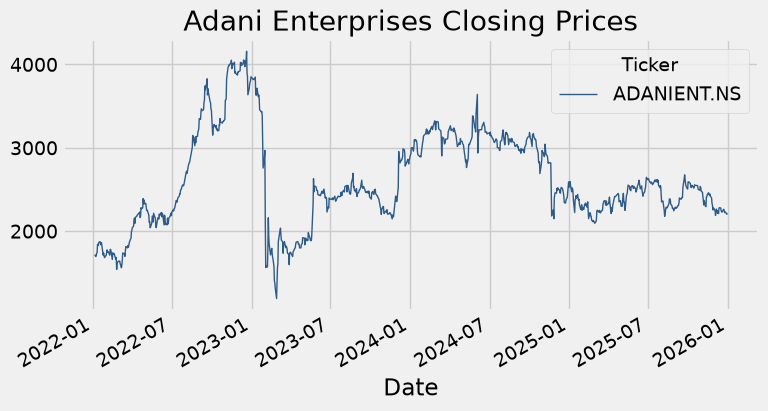

In [12]:
adani['Close'].plot(title = 'Adani Enterprises Closing Prices',figsize = (8,4),color='#2E5C8A',linewidth = 1)

<Axes: title={'center': 'Hindustan Unilever Closing Prices'}, xlabel='Date'>

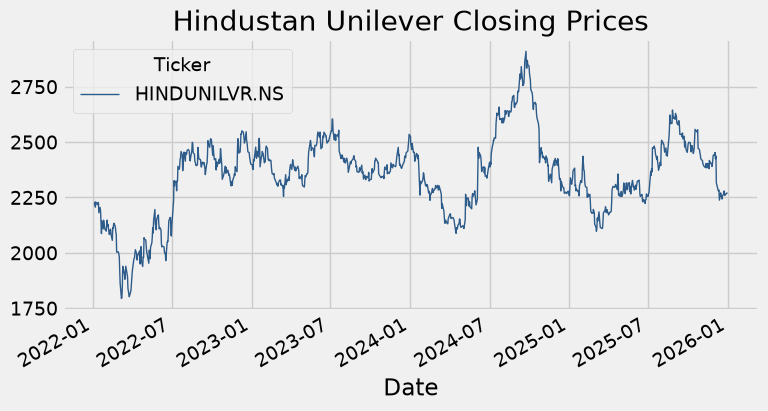

In [14]:
hul['Close'].plot(title='Hindustan Unilever Closing Prices',figsize = (8,4),linewidth = 1,color = '#2E5C8A')

<Axes: title={'center': 'Adani Enterprises Closing Price (Jan–Jul 2023)'}, xlabel='Date'>

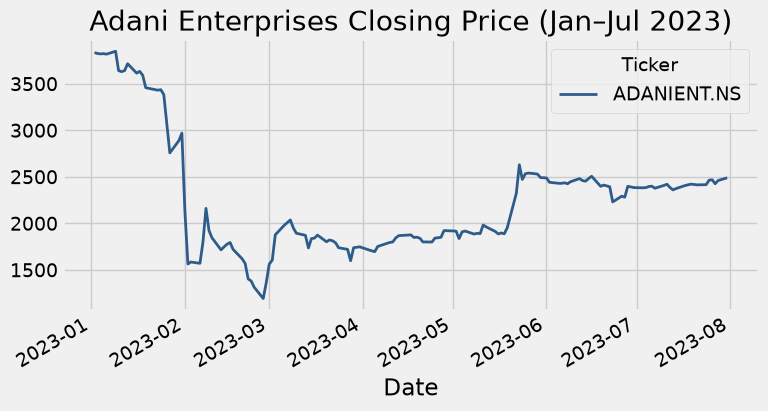

In [15]:
adani.loc['2023-01-01':'2023-07-31', 'Close'].plot(title='Adani Enterprises Closing Price (Jan–Jul 2023)', figsize=(8,4),linewidth = 2,color='#2E5C8A')

### Checking for normality

In [16]:
# Adani
jb_log_adani = stats.jarque_bera(adani['log_return'])
jb_arith_adani = stats.jarque_bera(adani['arith_return'])
sw_log_adani = stats.shapiro(adani['log_return'])
sw_arith_adani = stats.shapiro(adani['arith_return'])

print("ADANI - Log return - Jarque-Bera:", jb_log_adani)
print("ADANI - Arith return - Jarque-Bera:", jb_arith_adani)
print("ADANI - Log return - Shapiro-Wilk:", sw_log_adani)
print("ADANI - Arith return - Shapiro-Wilk:", sw_arith_adani)

ADANI - Log return - Jarque-Bera: SignificanceResult(statistic=np.float64(35425.411873272715), pvalue=np.float64(0.0))
ADANI - Arith return - Jarque-Bera: SignificanceResult(statistic=np.float64(19229.335034381154), pvalue=np.float64(0.0))
ADANI - Log return - Shapiro-Wilk: ShapiroResult(statistic=np.float64(0.7316825873670368), pvalue=np.float64(4.449302571983772e-37))
ADANI - Arith return - Shapiro-Wilk: ShapiroResult(statistic=np.float64(0.7604511922604309), pvalue=np.float64(1.5313952680240546e-35))


In [17]:
# HUL
jb_log_hul = stats.jarque_bera(hul['log_return'])
jb_arith_hul = stats.jarque_bera(hul['arith_return'])
sw_log_hul = stats.shapiro(hul['log_return'])
sw_arith_hul = stats.shapiro(hul['arith_return'])

print("HUL - Log return - Jarque-Bera:", jb_log_hul)
print("HUL - Arith return - Jarque-Bera:", jb_arith_hul)
print("HUL - Log return - Shapiro-Wilk:", sw_log_hul)
print("HUL - Arith return - Shapiro-Wilk:", sw_arith_hul)

HUL - Log return - Jarque-Bera: SignificanceResult(statistic=np.float64(500.1858091044683), pvalue=np.float64(2.432380929701231e-109))
HUL - Arith return - Jarque-Bera: SignificanceResult(statistic=np.float64(499.42064022002785), pvalue=np.float64(3.5660374677883413e-109))
HUL - Log return - Shapiro-Wilk: ShapiroResult(statistic=np.float64(0.9597319178733662), pvalue=np.float64(7.688906307877613e-16))
HUL - Arith return - Shapiro-Wilk: ShapiroResult(statistic=np.float64(0.9621693866195613), pvalue=np.float64(2.6552020923534922e-15))


##### Neither of them are normally distributed

### AIC / BIC

In [18]:
# Function for fitting different distributions and checking their scores
def fit_and_score(data, dist, name):
    params = dist.fit(data)
    loglik = np.sum(dist.logpdf(data, *params))
    k = len(params)
    n = len(data)
    aic = 2*k - 2*loglik
    bic = k*np.log(n) - 2*loglik
    print(f"{name}: AIC={aic:.2f}, BIC={bic:.2f}, params={params}")
    return aic, bic

In [19]:
data = adani['log_return'].values

print("=== Adani log returns ===")
fit_and_score(data, norm, "Normal")
fit_and_score(data, laplace, "Laplace")
fit_and_score(data, student_t, "Student-t")
fit_and_score(data, gennorm, "Generalized Error (GED)")

=== Adani log returns ===
Normal: AIC=-3946.83, BIC=-3937.04, params=(np.float64(0.0002598720299050322), np.float64(0.0326339899456849))
Laplace: AIC=-4579.90, BIC=-4570.11, params=(np.float64(0.0006526298680612767), np.float64(0.017995377636869845))
Student-t: AIC=-4676.83, BIC=-4662.15, params=(np.float64(1.9553966748158556), np.float64(0.0005723366383846612), np.float64(0.012934687707212584))
Generalized Error (GED): AIC=-4643.87, BIC=-4629.18, params=(np.float64(0.6890164914355688), np.float64(0.0007096591620695287), np.float64(0.0086220120691697))


(np.float64(-4643.865245522187), np.float64(-4629.184276458379))

In [20]:
import numpy as np
from scipy.stats import (norm, laplace, t as student_t, gennorm, logistic,
                          skewnorm, nct, johnsonsu, cauchy, genextreme)

distributions = {
    'Normal': norm,
    'Laplace': laplace,
    'Student-t': student_t,
    'GED': gennorm,
    'Logistic': logistic,
    'Skew-normal': skewnorm,
    'Skew-t (nct)': nct,
    'Johnson SU': johnsonsu,
    'Cauchy': cauchy,
    'GEV': genextreme
}

def fit_and_score(data, dist, name):
    try:
        params = dist.fit(data)
        loglik = np.sum(dist.logpdf(data, *params))
        k = len(params)
        n = len(data)
        aic = 2*k - 2*loglik
        bic = k*np.log(n) - 2*loglik
        return name, aic, bic, params
    except Exception as e:
        return name, np.nan, np.nan, str(e)

def run_all(data, label):
    print(f"\n=== {label} ===")
    results = []
    for name, dist in distributions.items():
        results.append(fit_and_score(data, dist, name))
    results_sorted = sorted(results, key=lambda x: x[1] if not np.isnan(x[1]) else np.inf)
    for name, aic, bic, params in results_sorted:
        print(f"{name:15s}  AIC={aic:10.2f}   BIC={bic:10.2f}")
    return results_sorted

adani_log_results = run_all(adani['log_return'].values, "Adani log returns")
adani_arith_results = run_all(adani['arith_return'].values, "Adani arith returns")
hul_log_results = run_all(hul['log_return'].values, "HUL log returns")
hul_arith_results = run_all(hul['arith_return'].values, "HUL arith returns")


=== Adani log returns ===
Student-t        AIC=  -4676.83   BIC=  -4662.15
Johnson SU       AIC=  -4675.73   BIC=  -4656.16
Skew-t (nct)     AIC=  -4674.87   BIC=  -4655.30
GED              AIC=  -4643.87   BIC=  -4629.18
Cauchy           AIC=  -4598.99   BIC=  -4589.20
Laplace          AIC=  -4579.90   BIC=  -4570.11
Logistic         AIC=  -4433.04   BIC=  -4423.25
Skew-normal      AIC=  -4007.62   BIC=  -3992.94
Normal           AIC=  -3946.83   BIC=  -3937.04
GEV              AIC=  -3511.33   BIC=  -3496.65

=== Adani arith returns ===
Student-t        AIC=  -4676.24   BIC=  -4661.56
Johnson SU       AIC=  -4676.06   BIC=  -4656.48
Skew-t (nct)     AIC=  -4674.65   BIC=  -4655.07
GED              AIC=  -4646.23   BIC=  -4631.55
Cauchy           AIC=  -4598.28   BIC=  -4588.50
Laplace          AIC=  -4587.32   BIC=  -4577.53
Logistic         AIC=  -4443.46   BIC=  -4433.67
Skew-normal      AIC=  -4026.06   BIC=  -4011.38
Normal           AIC=  -4001.67   BIC=  -3991.88
GEV          

###### student t is the best fit for every case

### Calculating parameters

In [24]:
n_days = 252

# Adani - GBM parameters
mu_daily_log_adani = adani['log_return'].mean()
sigma_daily_log_adani = adani['log_return'].std()

sigma_gbm_adani = sigma_daily_log_adani * np.sqrt(n_days)
mu_gbm_adani = mu_daily_log_adani * n_days + 0.5 * sigma_gbm_adani**2

print("Adani GBM -> sigma:", sigma_gbm_adani, " mu:", mu_gbm_adani)

# HUL - GBM parameters
mu_daily_log_hul = hul['log_return'].mean()
sigma_daily_log_hul = hul['log_return'].std()

sigma_gbm_hul = sigma_daily_log_hul * np.sqrt(n_days)
mu_gbm_hul = mu_daily_log_hul * n_days + 0.5 * sigma_gbm_hul**2

print("HUL GBM -> sigma:", sigma_gbm_hul, " mu:", mu_gbm_hul)

Adani GBM -> sigma: 0.5183113975929281  mu: 0.19981110397343557
HUL GBM -> sigma: 0.20195176591370959  mu: 0.030590167120802026


In [25]:
# Price differences (in ₹, not %)
adani['price_diff'] = adani['Close'].diff()
hul['price_diff'] = hul['Close'].diff()

adani_diff = adani['price_diff'].dropna()
hul_diff = hul['price_diff'].dropna()

# Adani - ABM parameters
mu_daily_diff_adani = adani_diff.mean()
sigma_daily_diff_adani = adani_diff.std()

sigma_abm_adani = sigma_daily_diff_adani * np.sqrt(n_days)
mu_abm_adani = mu_daily_diff_adani * n_days   # no log-correction needed for ABM

print("Adani ABM -> sigma (₹):", sigma_abm_adani, " mu (₹/year):", mu_abm_adani)

# HUL - ABM parameters
mu_daily_diff_hul = hul_diff.mean()
sigma_daily_diff_hul = hul_diff.std()

sigma_abm_hul = sigma_daily_diff_hul * np.sqrt(n_days)
mu_abm_hul = mu_daily_diff_hul * n_days

print("HUL ABM -> sigma (₹):", sigma_abm_hul, " mu (₹/year):", mu_abm_hul)

Adani ABM -> sigma (₹): 1266.5518069971693  mu (₹/year): 127.54495657519037
HUL ABM -> sigma (₹): 467.5504801238885  mu (₹/year): 13.25858185279188


#### Model using Dummy Option Values

In [26]:
S0_adani = 2962.5
r = 0.065  # dummy risk-free rate, ~6.5%, plausible current Indian T-bill level
dummy_options = pd.DataFrame({
    'K': [2700, 2800, 2900, 2800, 3000],
    'T_days': [30, 30, 30, 58, 58],
    'M': [210, 140, 85, 195, 110]   # dummy "real market prices"
})

dummy_options['T'] = dummy_options['T_days'] / 365  # convert to years
dummy_options

,K,T_days,M,T
0,2700,30,210,0.082192
1,2800,30,140,0.082192
2,2900,30,85,0.082192
3,2800,58,195,0.158904
4,3000,58,110,0.158904


##### Black Scholes Formula

In [27]:
def black_scholes_call(S0, K, T, r, sigma):
    d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

##### Bachelier Formula

In [28]:
def bachelier_call(S0, K, T, r, sigma):
    disc_K = K * np.exp(-r*T)
    if r == 0:
        scale = sigma * np.sqrt(T)
    else:
        scale = sigma * np.sqrt((1 - np.exp(-2*r*T)) / (2*r))
    d = (S0 - disc_K) / scale
    return (S0 - disc_K) * norm.cdf(d) + scale * norm.pdf(d)

In [29]:
dummy_options['C_BlackScholes'] = dummy_options.apply(
    lambda row: black_scholes_call(S0_adani, row['K'], row['T'], r, sigma_gbm_adani), axis=1
)

dummy_options['C_Bachelier'] = dummy_options.apply(
    lambda row: bachelier_call(S0_adani, row['K'], row['T'], r, sigma_abm_adani), axis=1
)

dummy_options

,K,T_days,M,T,C_BlackScholes,C_Bachelier
0,2700,30,210,0.082192,340.799736,323.202067
1,2800,30,140,0.082192,273.372830,250.182486
2,2900,30,85,0.082192,214.900933,186.783534
3,2800,58,195,0.158904,343.675125,310.374934
4,3000,58,110,0.158904,240.708086,197.064426


In [30]:
dummy_options['Error_BS_%'] = np.abs(dummy_options['C_BlackScholes'] - dummy_options['M']) / dummy_options['M'] * 100
dummy_options['Error_Bach_%'] = np.abs(dummy_options['C_Bachelier'] - dummy_options['M']) / dummy_options['M'] * 100

dummy_options

,K,T_days,M,T,C_BlackScholes,C_Bachelier,Error_BS_%,Error_Bach_%
0,2700,30,210,0.082192,340.799736,323.202067,62.285588,53.905746
1,2800,30,140,0.082192,273.372830,250.182486,95.266307,78.701776
2,2900,30,85,0.082192,214.900933,186.783534,152.824627,119.745334
3,2800,58,195,0.158904,343.675125,310.374934,76.243654,59.166633
4,3000,58,110,0.158904,240.708086,197.064426,118.825533,79.149478


In [31]:
mape_bs = dummy_options['Error_BS_%'].mean()
mape_bach = dummy_options['Error_Bach_%'].mean()

print("Black-Scholes MAPE:", mape_bs)
print("Bachelier MAPE:", mape_bach)

winner = "Black-Scholes" if mape_bs < mape_bach else "Bachelier"
print("Better model (lower MAPE):", winner)

Black-Scholes MAPE: 101.08914175976727
Bachelier MAPE: 78.13379335714994
Better model (lower MAPE): Bachelier


In [ ]:
import numpy as np

def hybrid_euler_call(S0, K, T, r, mu1, mu2, sigma1, sigma2, rho, lam, n_paths=20000, n_steps=100, seed=42):
    """
    Computes European Call option price using vectorized Euler-Maruyama discretization.
    """
    if T <= 0:
        return max(S0 - K, 0.0)
    
    dt = T / n_steps
    rng = np.random.default_rng(seed)
    
    # Initialize all paths at S0
    S = np.full(n_paths, S0, dtype=np.float64)
    
    # March forward from t=0 to t=T
    for _ in range(n_steps):
        # Combined diffusion term under the hybrid model
        diff = np.maximum(sigma1**2 + sigma2**2 * S**2 + 2 * rho * sigma1 * sigma2 * S, 0.0)
        vol = np.sqrt(diff)
        
        # Risk-neutral drift including the market price of risk (lambda)
        drift = (mu1 - mu2 * S) - lam * vol
        
        # Random normal shocks
        Z = rng.standard_normal(n_paths)
        
        # Euler step: S_{t+dt} = S_t + drift * dt + vol * sqrt(dt) * Z
        S = S + drift * dt + vol * np.sqrt(dt) * Z
        
        # Floor price at zero to prevent negative values
        S = np.maximum(S, 0.0)
        
    # Calculate payoff max(S_T - K, 0) and continuously discount back to t=0
    payoff = np.maximum(S - K, 0.0)
    return float(np.exp(-r * T) * np.mean(payoff))


dummy_options['C_Euler'] = dummy_options.apply(
    lambda row: hybrid_euler_call(
        S0=S0_adani,
        K=row['K'],
        T=row['T'],
        r=r,
        mu1=params_adani['mu1'],
        mu2=params_adani['mu2'],
        sigma1=params_adani['sigma1'],
        sigma2=params_adani['sigma2'],
        rho=params_adani['rho'],
        lam=-0.05  # Calibrated risk parameter
    ),
    axis=1
)

# 2. Compute Percentage Error for Euler model
dummy_options['Error_Euler_%'] = np.abs(dummy_options['C_Euler'] - dummy_options['M']) / dummy_options['M'] * 100

# 3. Compute Mean Absolute Percentage Error (MAPE)
mape_euler = dummy_options['Error_Euler_%'].mean()

print("Black-Scholes MAPE :", round(mape_bs, 2), "%")
print("Bachelier MAPE     :", round(mape_bach, 2), "%")
print("Hybrid Euler MAPE  :", round(mape_euler, 2), "%")

# Find overall best model
mapes = {
    "Black-Scholes": mape_bs,
    "Bachelier": mape_bach,
    "Hybrid Euler": mape_euler
}
best_model = min(mapes, key=mapes.get)
print(f"Overall Best Model (lowest MAPE): {best_model}")

NameError: name 'params_adani' is not defined

In [6]:
adani.tail()

Price,Close,High,Low,Open,Volume,log_return,arith_return
Ticker,ADANIENT.NS,ADANIENT.NS,ADANIENT.NS,ADANIENT.NS,ADANIENT.NS,,
Date,,,,,,,
2025-12-23,2247.794922,2272.583886,2243.996572,2271.484280,450112,-0.006516,-0.006494
2025-12-24,2221.706543,2257.790506,2216.408863,2248.994390,825693,-0.011674,-0.011606
2025-12-26,2228.903320,2249.893935,2217.008736,2228.303735,566237,0.003234,0.003239
2025-12-29,2202.215332,2237.199690,2195.018599,2231.002510,690691,-0.012046,-0.011974
2025-12-30,2213.710205,2218.008332,2194.019058,2203.814727,935026,0.005206,0.005220


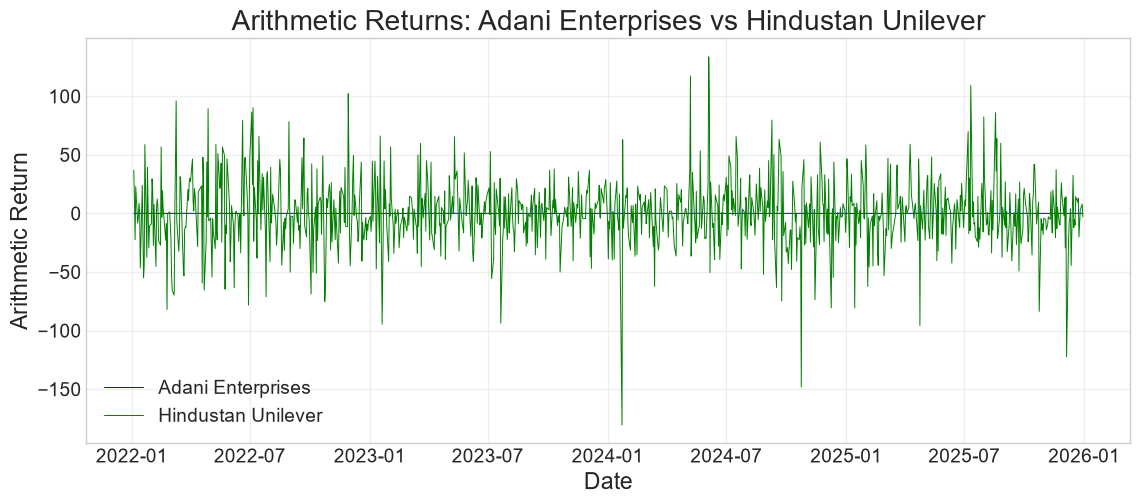

In [54]:
# Plot
plt.figure(figsize=(12, 5))

plt.plot(adani.index, adani['arith_return'],
         label='Adani Enterprises', linewidth=0.7,color='blue')

plt.plot(hul.index, hul['arith_return'],
         label='Hindustan Unilever', linewidth=0.7, color ='green')

plt.title('Arithmetic Returns: Adani Enterprises vs Hindustan Unilever')
plt.xlabel('Date')
plt.ylabel('Arithmetic Return')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

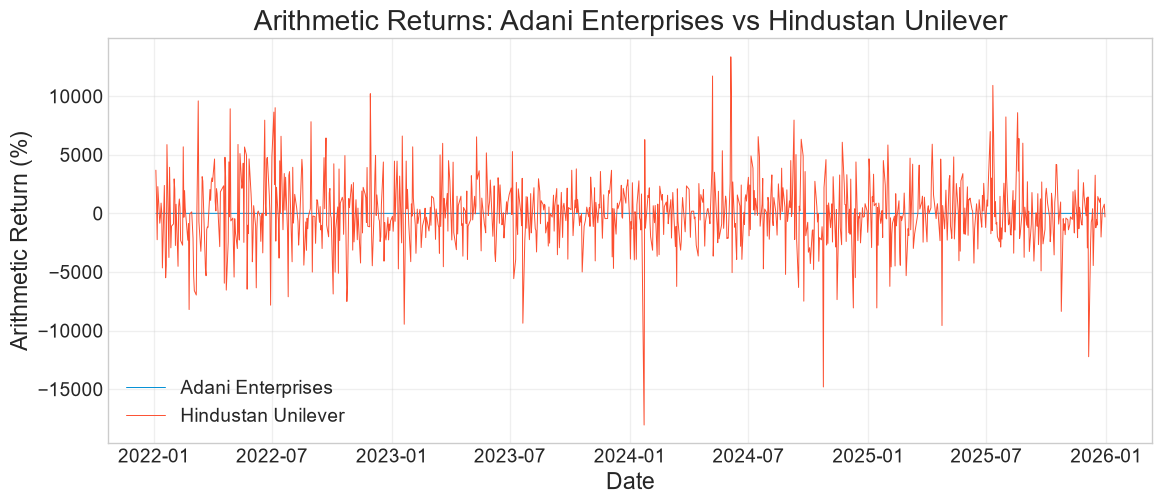

In [55]:
plt.figure(figsize=(12, 5))

plt.plot(adani.index, adani['arith_return'] * 100,
         label='Adani Enterprises', linewidth=0.7)

plt.plot(hul.index, hul['arith_return'] * 100,
         label='Hindustan Unilever', linewidth=0.7)

plt.title('Arithmetic Returns: Adani Enterprises vs Hindustan Unilever')
plt.xlabel('Date')
plt.ylabel('Arithmetic Return (%)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

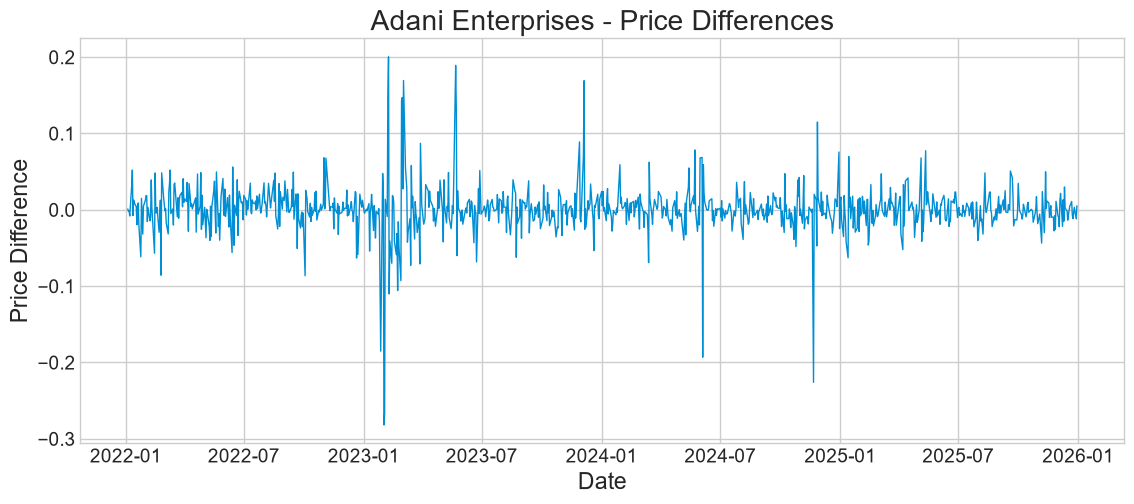

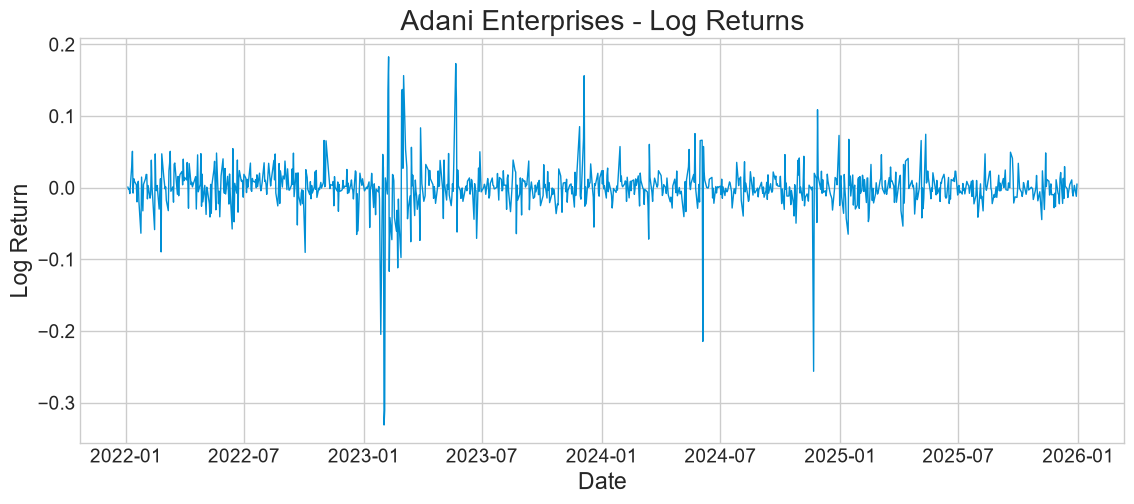

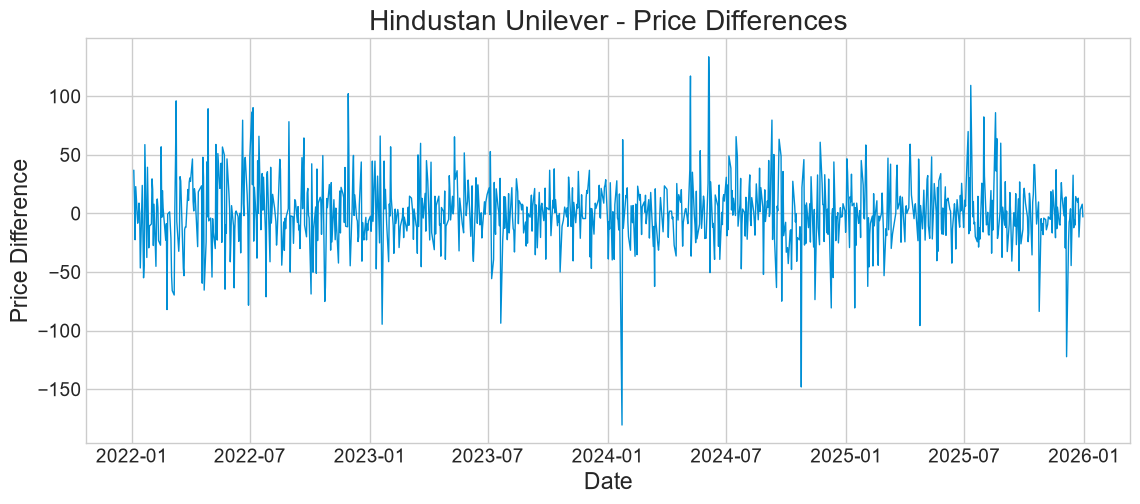

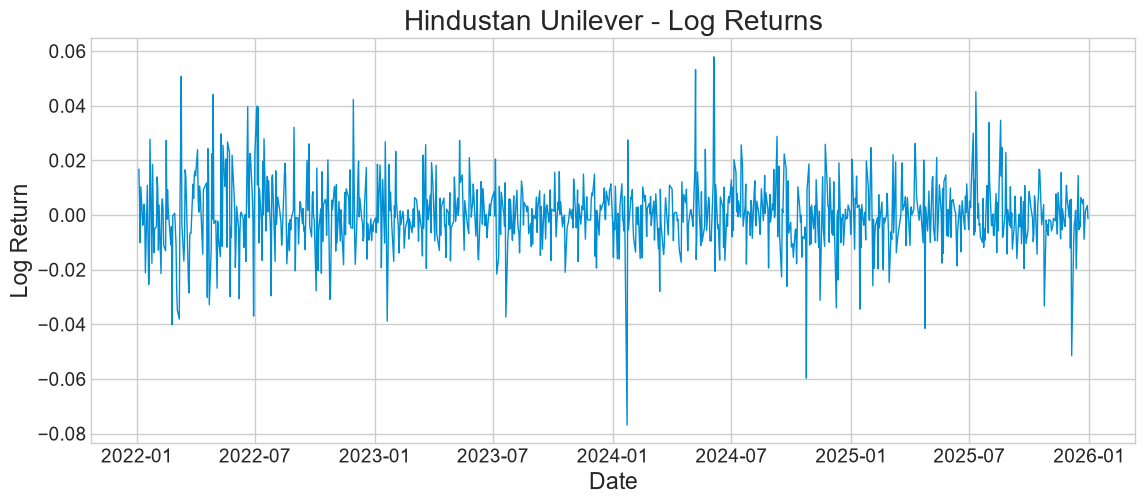

In [57]:
import matplotlib.pyplot as plt

# -----------------------------
# ADANI ENTERPRISES
# -----------------------------

plt.figure(figsize=(12, 5))
plt.plot(adani.index, adani['arith_return'],linewidth=1)
plt.title('Adani Enterprises - Price Differences')
plt.xlabel('Date')
plt.ylabel('Price Difference')
plt.grid(True)
plt.show()


plt.figure(figsize=(12, 5))
plt.plot(adani.index, adani['log_return'],linewidth=1)
plt.title('Adani Enterprises - Log Returns')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.grid(True)
plt.show()


# -----------------------------
# HINDUSTAN UNILEVER
# -----------------------------

plt.figure(figsize=(12, 5))
plt.plot(hul.index, hul['arith_return'],linewidth=1)
plt.title('Hindustan Unilever - Price Differences')
plt.xlabel('Date')
plt.ylabel('Price Difference')
plt.grid(True)
plt.show()


plt.figure(figsize=(12, 5))
plt.plot(hul.index, hul['log_return'],linewidth=1)
plt.title('Hindustan Unilever - Log Returns')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.grid(True)
plt.show()

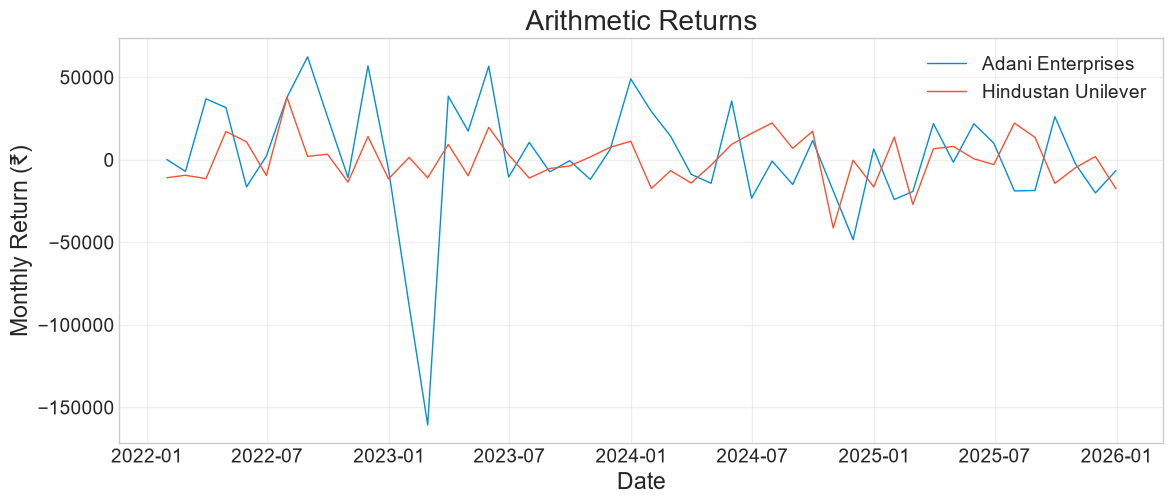

In [69]:
adani_monthly = adani['arith_return'].resample('ME').sum()
hul_monthly = hul['arith_return'].resample('ME').sum()

plt.figure(figsize=(12, 5))

plt.plot(adani_monthly.index, adani_monthly * 100,
         label='Adani Enterprises', linewidth=1)

plt.plot(hul_monthly.index, hul_monthly * 100,
         label='Hindustan Unilever', linewidth=1)

plt.xlabel('Date')
plt.ylabel('Monthly Return (₹)')
plt.title('Arithmetic Returns')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

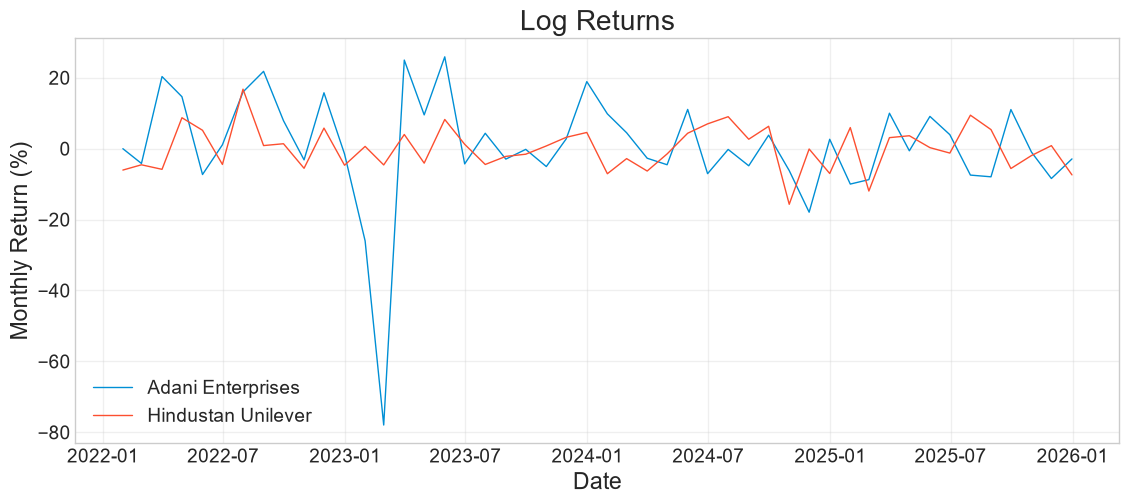

In [67]:
adani_monthly = adani['log_return'].resample('ME').sum()
hul_monthly = hul['log_return'].resample('ME').sum()

plt.figure(figsize=(12, 5))

plt.plot(adani_monthly.index, adani_monthly * 100,
         label='Adani Enterprises', linewidth=1)

plt.plot(hul_monthly.index, hul_monthly * 100,
         label='Hindustan Unilever', linewidth=1)

plt.xlabel('Date')
plt.ylabel('Monthly Return (%)')
plt.title('Log Returns')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

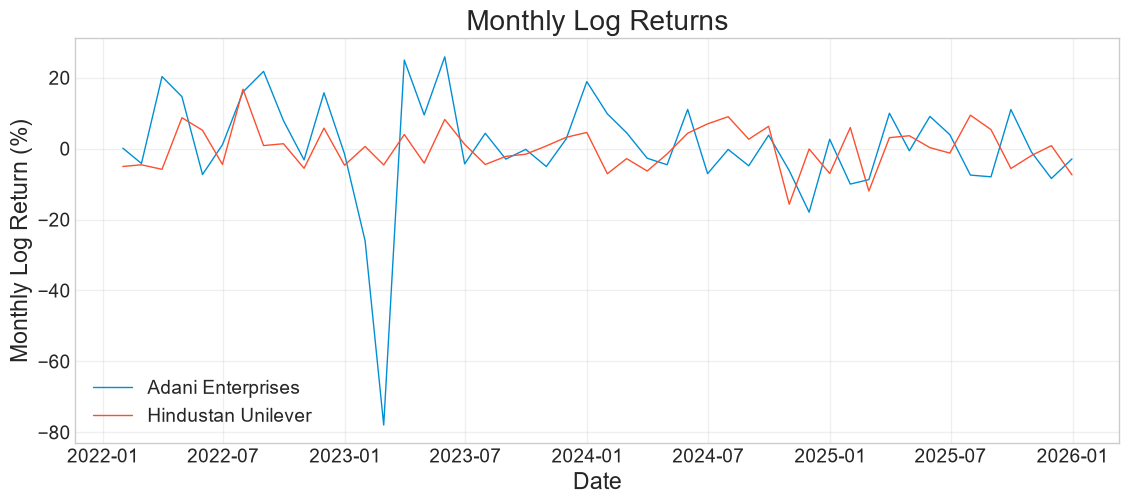

In [70]:
adani_monthly = adani['log_return'].resample('ME').sum()
hul_monthly = hul['log_return'].resample('ME').sum()

plt.figure(figsize=(12, 5))

plt.plot(adani_monthly.index, adani_monthly * 100,
         label='Adani Enterprises', linewidth=1)

plt.plot(hul_monthly.index, hul_monthly * 100,
         label='Hindustan Unilever', linewidth=1)

plt.xlabel('Date')
plt.ylabel('Monthly Log Return (%)')
plt.title('Monthly Log Returns')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [71]:
adani_monthly

Date
2022-01-31    0.001079
2022-02-28   -0.041978
2022-03-31    0.203089
2022-04-30    0.146231
2022-05-31   -0.073129
2022-06-30    0.010715
2022-07-31    0.159694
2022-08-31    0.217789
2022-09-30    0.078656
2022-10-31   -0.031841
2022-11-30    0.157357
2022-12-31   -0.015316
2023-01-31   -0.260365
2023-02-28   -0.779563
2023-03-31    0.249561
2023-04-30    0.095027
2023-05-31    0.258727
2023-06-30   -0.043150
2023-07-31    0.043173
2023-08-31   -0.029708
2023-09-30   -0.002214
2023-10-31   -0.050663
2023-11-30    0.027467
2023-12-31    0.188904
2024-01-31    0.097909
2024-02-29    0.044629
2024-03-31   -0.027244
2024-04-30   -0.045563
2024-05-31    0.110427
2024-06-30   -0.070733
2024-07-31   -0.002442
2024-08-31   -0.048501
2024-09-30    0.037859
2024-10-31   -0.062028
2024-11-30   -0.179432
2024-12-31    0.026245
2025-01-31   -0.100095
2025-02-28   -0.087560
2025-03-31    0.099724
2025-04-30   -0.006281
2025-05-31    0.090745
2025-06-30    0.039222
2025-07-31   -0.074766
2025-0

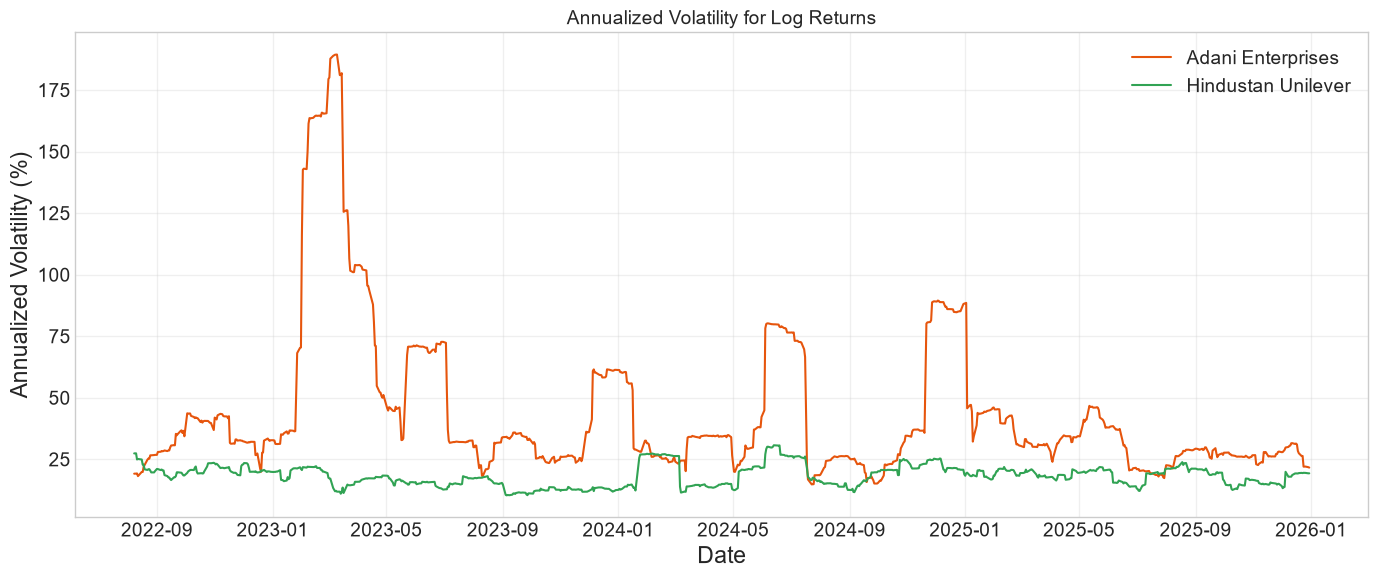

In [76]:
window = 30  # trading days
trading_days_per_year = 252

adani["rolling_vol"] = adani["log_return"].rolling(window).std() * np.sqrt(trading_days_per_year) * 100
hul["rolling_vol"]   = hul["log_return"].rolling(window).std() * np.sqrt(trading_days_per_year) * 100

adani.dropna(inplace=True)
hul.dropna(inplace=True)

# ---------------------------------------------------------
# 4. Plot rolling volatility comparison
# ---------------------------------------------------------
plt.figure(figsize=(14, 6))
plt.plot(adani.index, adani["rolling_vol"], label="Adani Enterprises", color="#e6550d", linewidth=1.5)
plt.plot(hul.index, hul["rolling_vol"], label="Hindustan Unilever", color="#31a354", linewidth=1.5)

plt.title("Annualized Volatility for Log Returns", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Annualized Volatility (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("volatility_comparison_log.png", dpi=300)  # saves the plot as an image
plt.show()


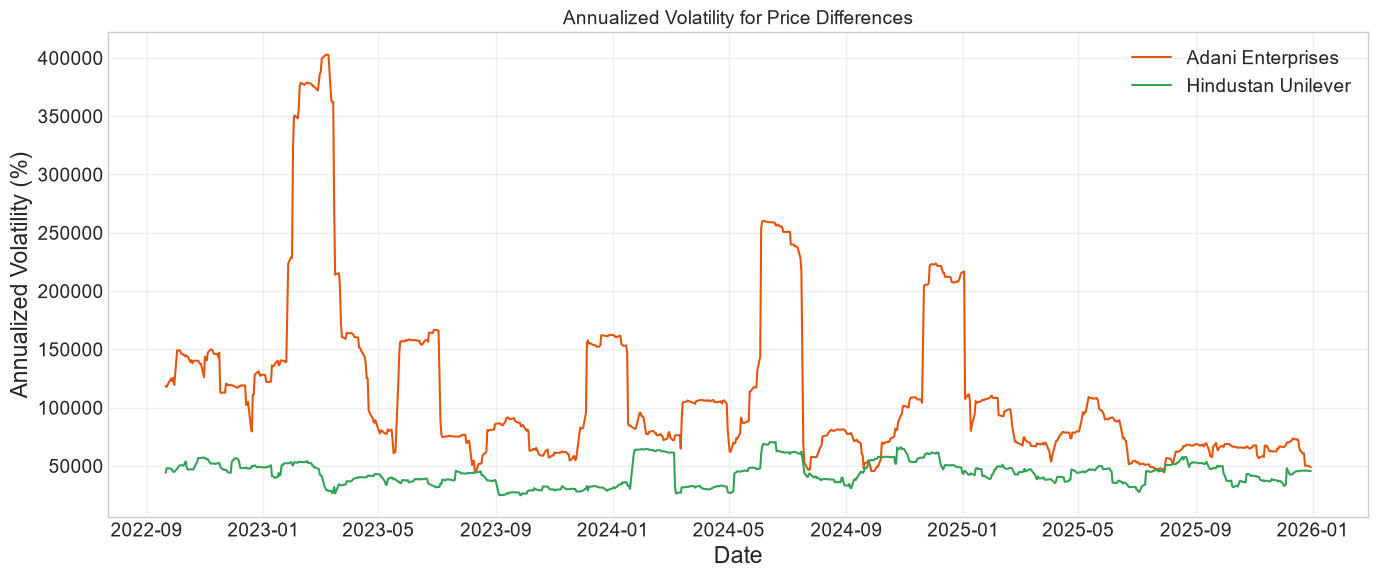

In [77]:
window = 30  # trading days
trading_days_per_year = 252

adani["rolling_vol"] = adani["arith_return"].rolling(window).std() * np.sqrt(trading_days_per_year) * 100
hul["rolling_vol"]   = hul["arith_return"].rolling(window).std() * np.sqrt(trading_days_per_year) * 100

adani.dropna(inplace=True)
hul.dropna(inplace=True)

# ---------------------------------------------------------
# 4. Plot rolling volatility comparison
# ---------------------------------------------------------
plt.figure(figsize=(14, 6))
plt.plot(adani.index, adani["rolling_vol"], label="Adani Enterprises", color="#e6550d", linewidth=1.5)
plt.plot(hul.index, hul["rolling_vol"], label="Hindustan Unilever", color="#31a354", linewidth=1.5)

plt.title("Annualized Volatility for Price Differences", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Annualized Volatility (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("volatility_comparison.png", dpi=300)  # saves the plot as an image
plt.show()


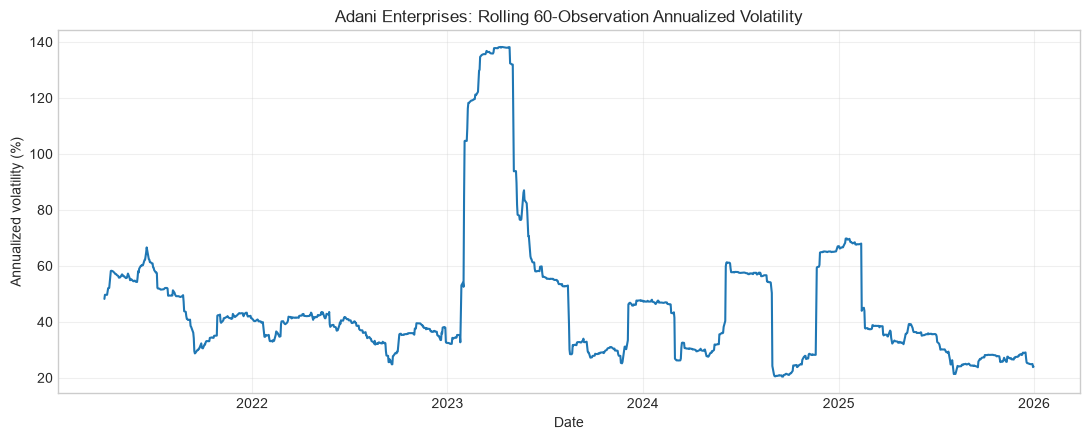

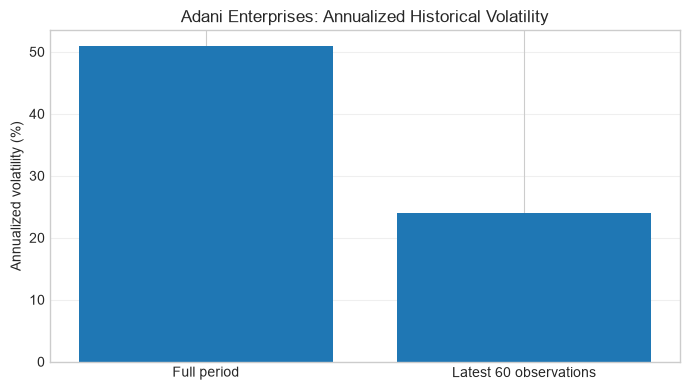

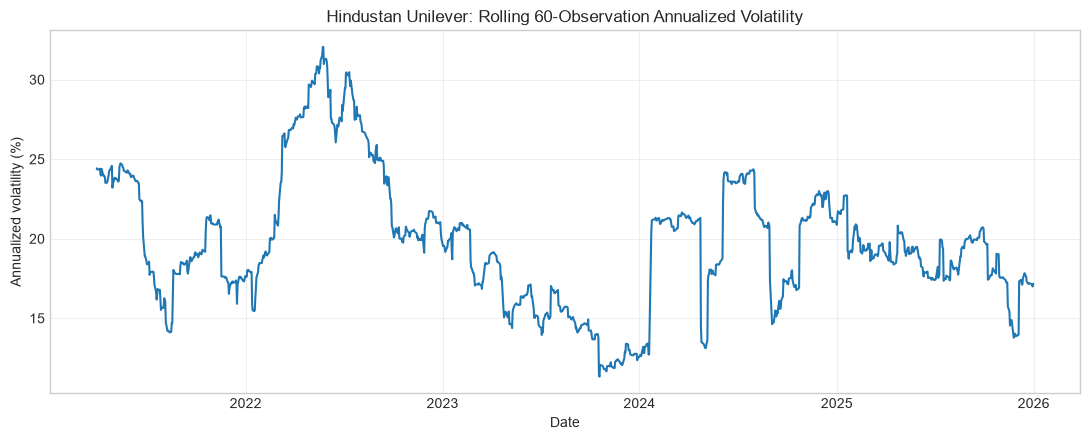

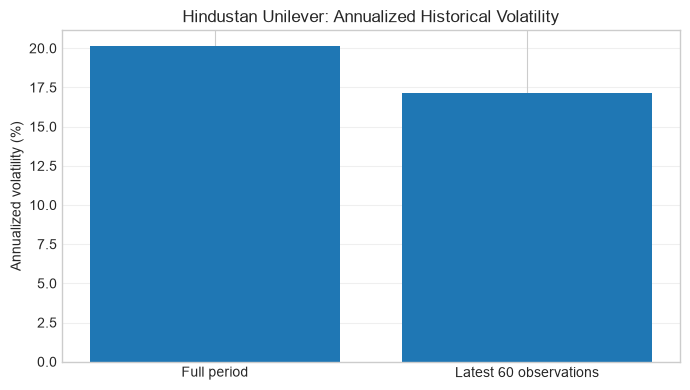

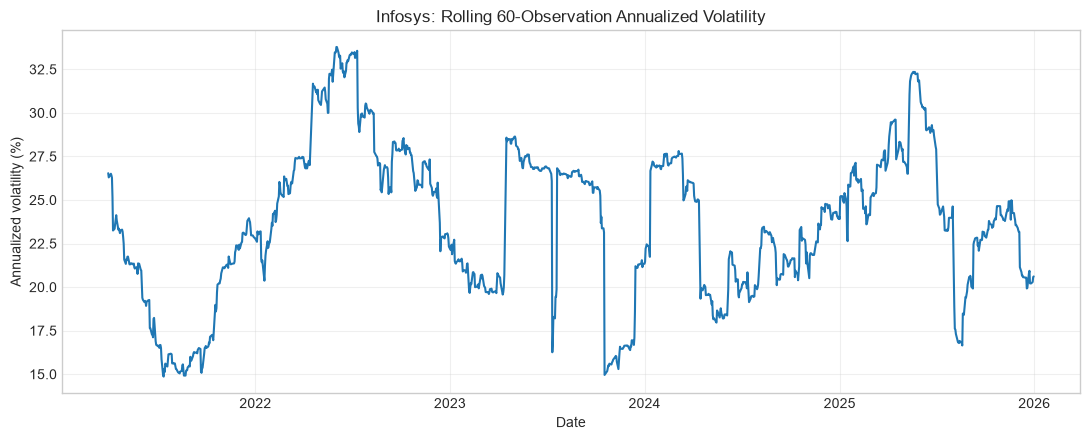

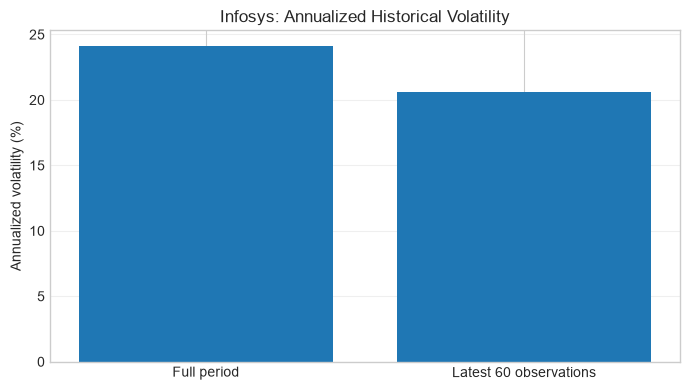

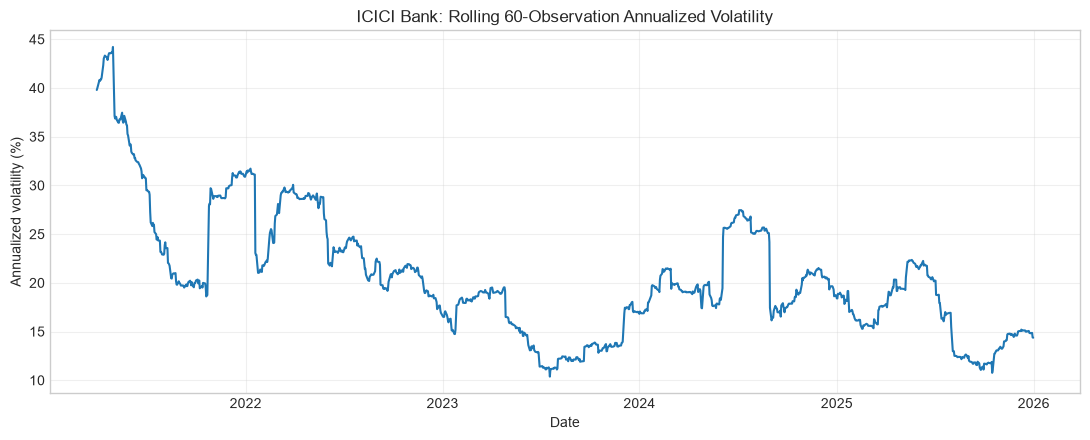

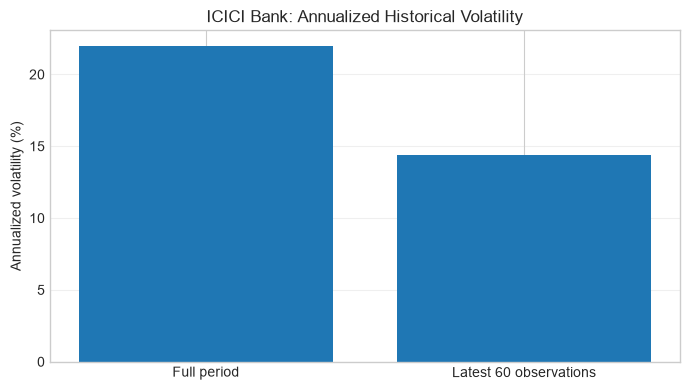

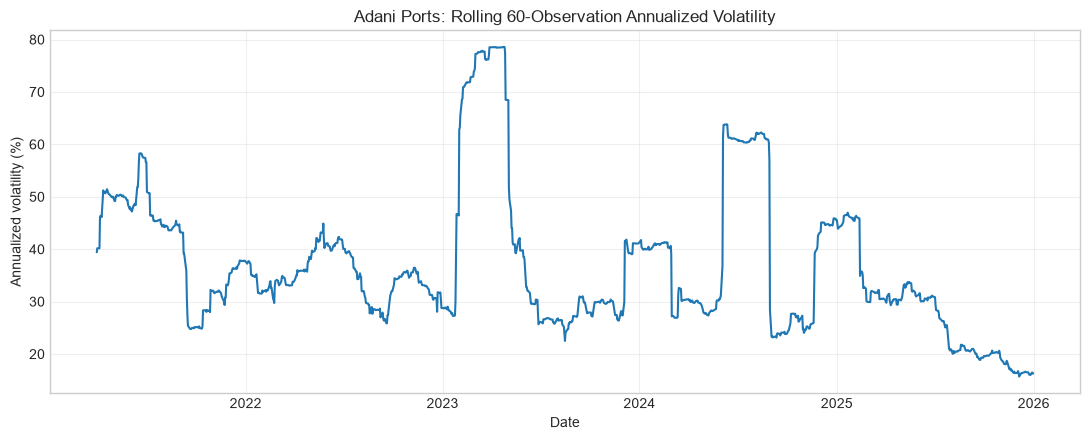

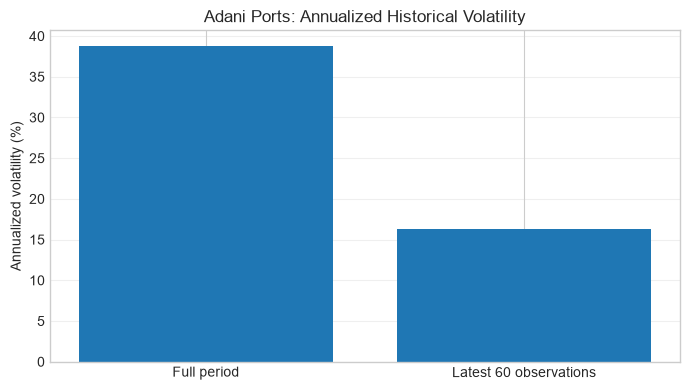

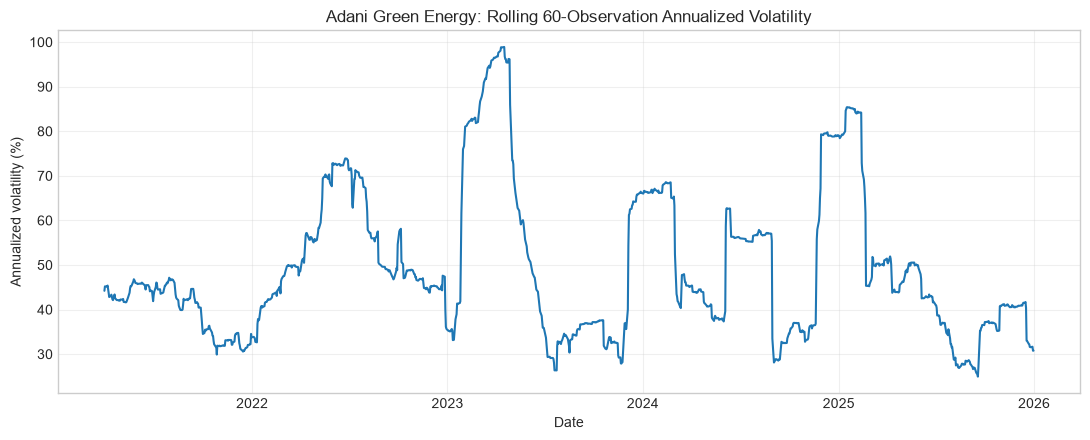

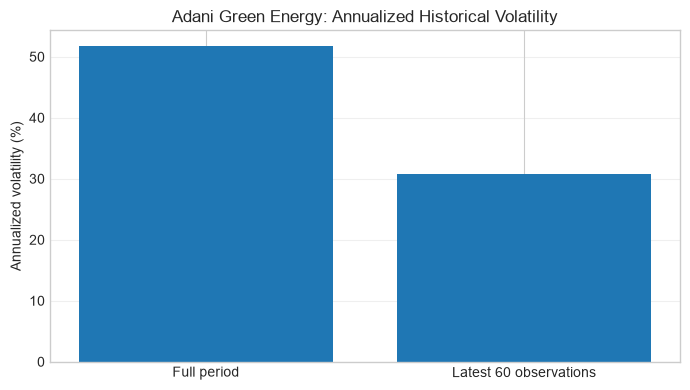

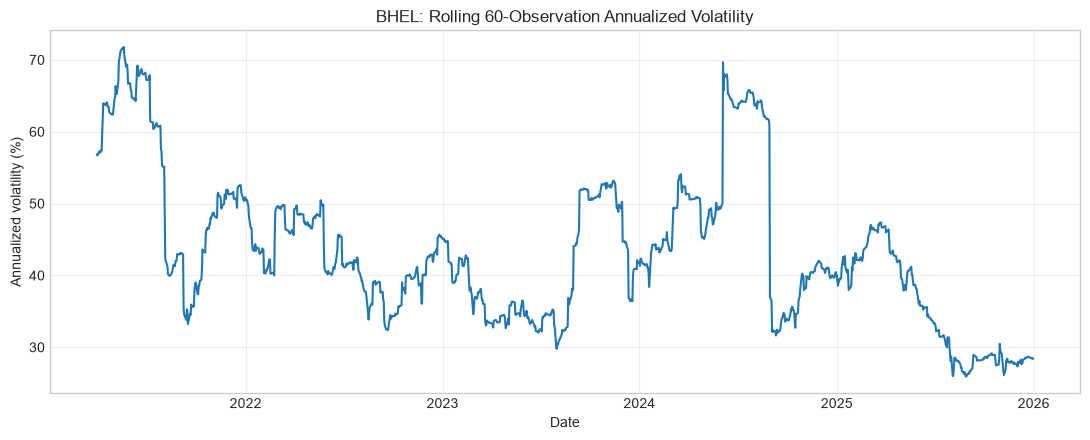

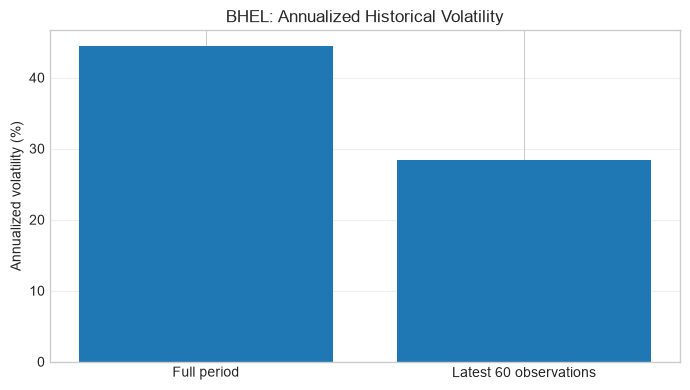

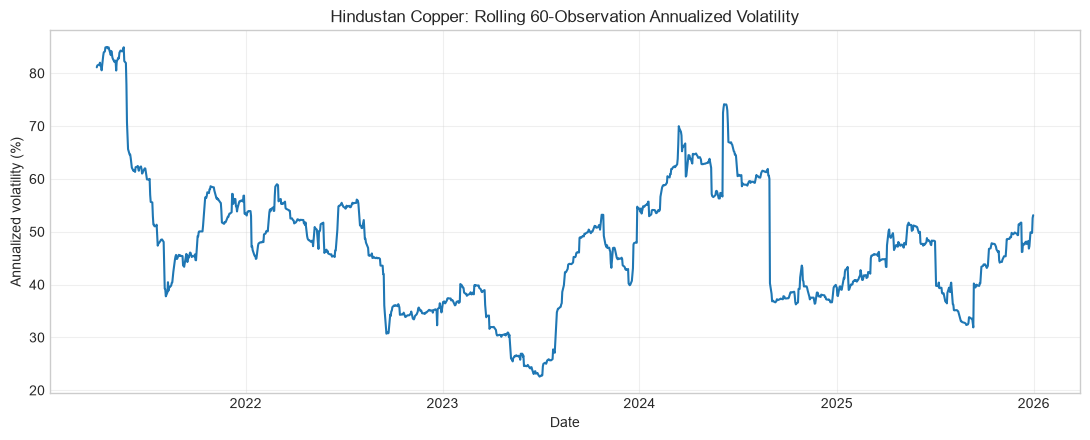

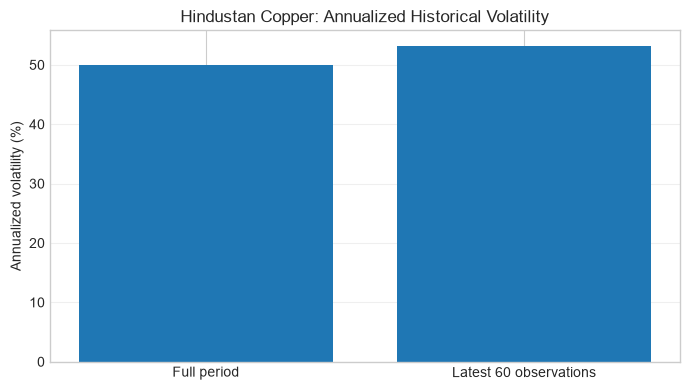

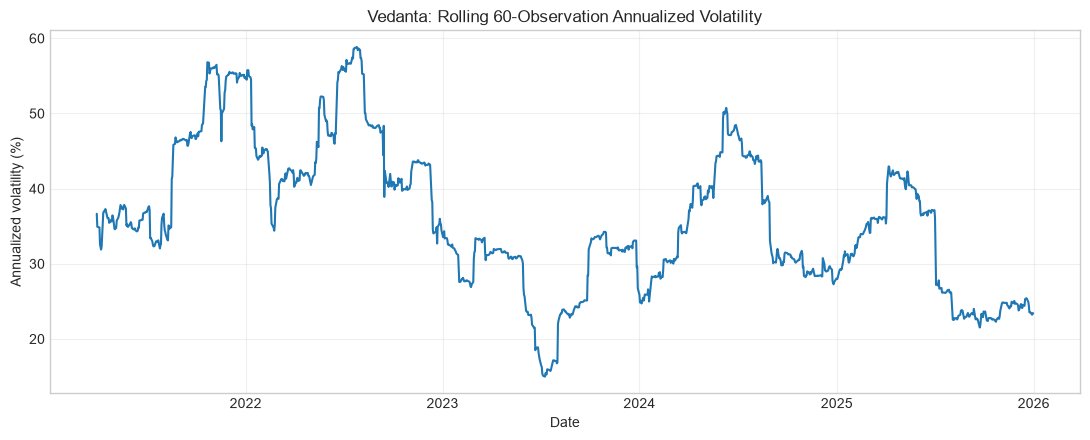

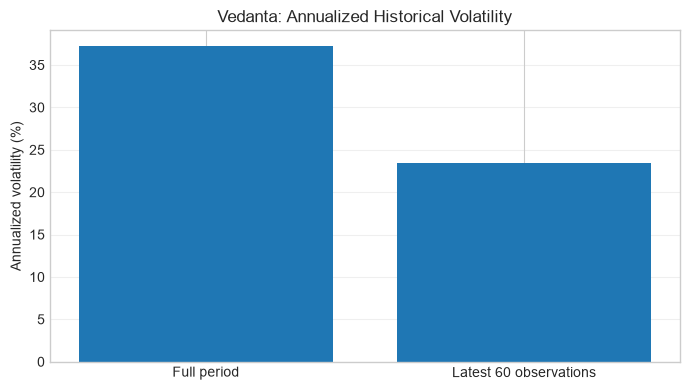

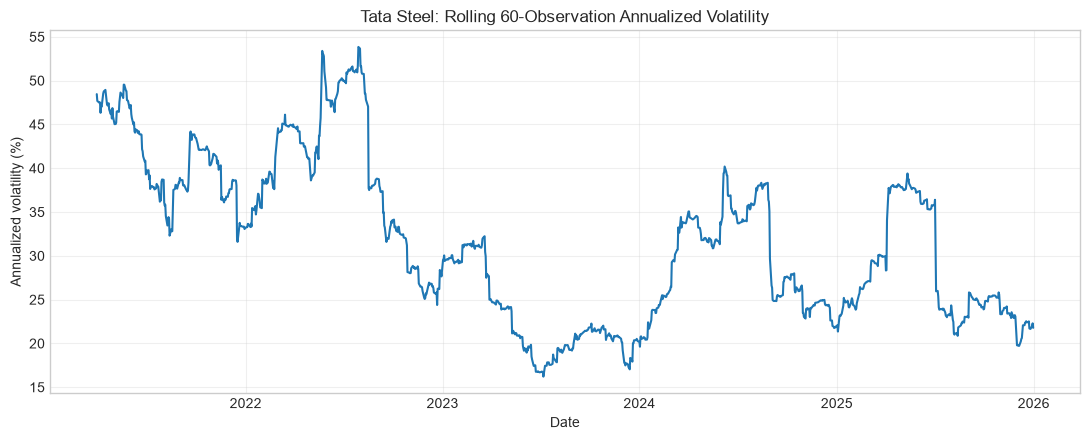

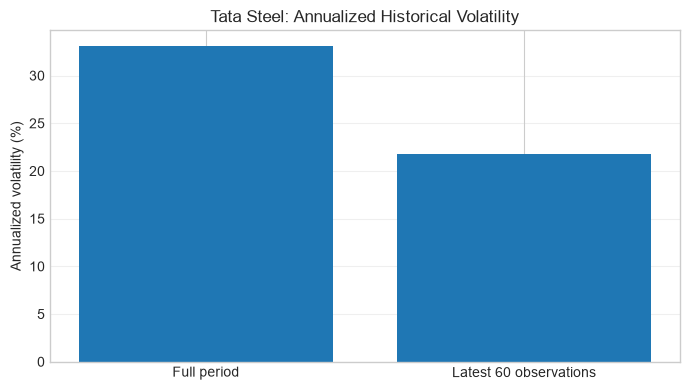

,Stock,Ticker,First price date,Full-period volatility (%),Latest 60-observation volatility (%),Number of returns
0,Adani Green Energy,ADANIGREEN.NS,2021-01-01,51.71,30.78,1235
1,Adani Enterprises,ADANIENT.NS,2021-01-01,50.89,23.98,1235
2,Hindustan Copper,HINDCOPPER.NS,2021-01-01,50.05,53.13,1235
3,BHEL,BHEL.NS,2021-01-01,44.41,28.40,1235
4,Adani Ports,ADANIPORTS.NS,2021-01-01,38.74,16.29,1235
5,Vedanta,VEDL.NS,2021-01-01,37.21,23.40,1235
6,Tata Steel,TATASTEEL.NS,2021-01-01,33.07,21.78,1235
7,Infosys,INFY.NS,2021-01-01,24.10,20.61,1235
8,ICICI Bank,ICICIBANK.NS,2021-01-01,21.96,14.36,1235
9,Hindustan Unilever,HINDUNILVR.NS,2021-01-01,20.13,17.17,1235


In [5]:

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

tickers = {
    "Adani Enterprises": "ADANIENT.NS",
    "Hindustan Unilever": "HINDUNILVR.NS",
    "Infosys": "INFY.NS",
    "ICICI Bank": "ICICIBANK.NS",
    "Adani Ports": "ADANIPORTS.NS",
    "Adani Green Energy": "ADANIGREEN.NS",
    "BHEL": "BHEL.NS",
    "Hindustan Copper": "HINDCOPPER.NS",
    "Vedanta": "VEDL.NS",
    "Tata Steel": "TATASTEEL.NS"
}

TRADING_DAYS = 252
START_DATE = "2021-01-01"
END_DATE = "2026-01-01"

summary_rows = []
rolling_vols = {}

for name, ticker in tickers.items():
    try:
        data = yf.download(
            ticker,
            start=START_DATE,
            end=END_DATE,
            auto_adjust=True,
            progress=False
        )

        if data.empty:
            print(f"Skipping {name}: no price data returned.")
            continue

        close = data["Close"]
        if isinstance(close, pd.DataFrame):
            close = close.iloc[:, 0]
        close = close.dropna()

        log_returns = np.log(close / close.shift(1)).dropna()

        if len(log_returns) < 60:
            print(f"Skipping {name}: fewer than 60 returns.")
            continue

        full_vol = log_returns.std(ddof=1) * np.sqrt(TRADING_DAYS) * 100
        recent_vol = (
            log_returns.tail(60).std(ddof=1)
            * np.sqrt(TRADING_DAYS) * 100
        )

        rolling_vol = (
            log_returns.rolling(60).std(ddof=1)
            * np.sqrt(TRADING_DAYS) * 100
        )

        rolling_vols[name] = rolling_vol

        summary_rows.append({
            "Stock": name,
            "Ticker": ticker,
            "First price date": close.index.min().date(),
            "Full-period volatility (%)": full_vol,
            "Latest 60-observation volatility (%)": recent_vol,
            "Number of returns": len(log_returns)
        })

        # Graph 1: individual rolling-volatility graph
        plt.figure(figsize=(11, 4.5))
        plt.plot(rolling_vol.index, rolling_vol.values)
        plt.title(f"{name}: Rolling 60-Observation Annualized Volatility")
        plt.xlabel("Date")
        plt.ylabel("Annualized volatility (%)")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Graph 2: individual full-period vs recent-volatility graph
        plt.figure(figsize=(7, 4))
        plt.bar(
            ["Full period", "Latest 60 observations"],
            [full_vol, recent_vol]
        )
        plt.title(f"{name}: Annualized Historical Volatility")
        plt.ylabel("Annualized volatility (%)")
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Error for {name} ({ticker}): {e}")

# Rank stocks using the same historical period where possible
summary_df = pd.DataFrame(summary_rows)

if not summary_df.empty:
    summary_df = summary_df.sort_values(
        "Full-period volatility (%)",
        ascending=False
    ).reset_index(drop=True)

    display(summary_df.round(2))
